This is just a notebook to practice backpropogation manually instead of use the pytorch function loss.backward() to do everything on machine. 

* Firstly we are going to backpropogation step by step. 
* Secondly we are going to use math to skip the steps that can. be put together in a more concise way. 
* And after we have done all that we are going to substitute the pytorch function with all the backpropogation code we write ourselves to see the result. 

## Preparation

In [1]:
import torch
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

# read file
words = open('../names.txt', 'r').read().splitlines()
words[:10]

# mapping from letters to numbers and reverse
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos) # 27

# turning the dataset into the structure of [input] [desired output]
block_size = 3 
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# split the dataset (tr/dev/ts) (80/10/10)
def build_dataset(words):
    block_size = 3
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


Also, since we are to back propogate by hand, we need to know the accuracy of the gradients we calculate ourselves. Therefore, we create another function below:

In [2]:
# utility function used to compare manual gradient to PyTorch gradients
def cmp(s, dt, t):
    ex = torch.all(dt == t.grad).item() # dt is the grad we calculate
    # exact equality
    app = torch.allclose(dt, t.grad) # return if all elements match within acceptable margins
    # approximate equality
    # |inputi - otheri| < absolute_tolerance + relative_tolerance * |otheri|
    maxdiff = (dt - t.grad).abs().max().item()
    print(f'{s:15s} | {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}')

# Pytorch backpropogation

### Parameters Initialization

Here we made somce change on the parameters initialization in the note4. 

* b1 comes back to existence although it does not add anything to the training loop. Here we add it just ot add fun to the manual backpropogation. 
* we remove bnmean_running and bnstd_running since we are going to use predeterministic mean/std instead of a running one. 

In [3]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 64 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 * (1/(n_embd * block_size)**0.5)
b1 = torch.randn(n_hidden,                          generator = g) * 0.1 # added back though useless
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * (1/(n_hidden)**0.5)
b2 = torch.randn(vocab_size,                        generator = g) * 0.1 # changed

bngain = torch.randn((1, n_hidden)) * 0.1 + 1.0 # changed
bnbias = torch.randn((1, n_hidden)) * 0.1 # changed

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

4137


### Training loop (only executed once so no for loop)

For the training loop, we will not use those functions which integrate many different basic operations together since that increases the difficulty of backpropogating step by step, and therefore we will break down them down into more basic operations. 

And before that, we clarify standardization and normalization of data. 

#### 1. Normalization (Min-Max Scaling)
$$X_{norm} = \frac{X - X_{min}}{X_{max} - X_{min}}$$

#### 2. Standardization (Z-Score)
$$X_{std} = \frac{X - \mu}{\sigma}$$

**Where:**
* $X$ is the original data point.
* $X_{min}$ and $X_{max}$ are the minimum and maximum values of the feature.
* $\mu$ is the mean of the feature.
* $\sigma$ is the standard deviation of the feature.

In this scenario of normalization, we subtract the maximum from each entry without scaling since scaling affects the probablity in calculating the cross-entropy loss. 

In this scenario of standardization, we use the standard deviation of the unbiased version, which use ```m-1``` instead of ```m```. Also, we add a epsilon under the square root in the denominator in order to prevent the case where the variance is exactly zero: 

#### 1. Compute the Variance ($\sigma^2$)
$$ \sigma^2 = \frac{1}{m-1} \sum_{i=1}^{m} (x_i - \mu)^2 $$

#### 2. Apply Normalization (with $\epsilon$)
$$ x' = \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} $$

In [4]:
batch_size = 32
n = batch_size # a shorter expression for convenience of calculation
# construction of minibatch
ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
Xb, Yb = Xtr[ix], Ytr[ix]

eps = 1e-5
emb = C[Xb] # 32, 3, 10
embcat = emb.view(n, -1) # 32, 30
# linear layer 1
hprebn = embcat @ W1 + b1 # 32, 64
# batchnorm layer
bnmean = 1/n * hprebn.sum(0, keepdims = True) # 1, 64
bndiff = hprebn - bnmean # bnmean broadcasted vertically, 32, 64
bndiff_sq = bndiff ** 2 # 32, 64
bnvar = 1/(n-1) * bndiff_sq.sum(0, keepdims = True) # 1, 64
bnvar_inv = (bnvar + eps) ** -0.5 # 1, 64
bnraw = bndiff * bnvar_inv # bnvar_inv broadcasted vertically, 32, 64
hpreact = bngain * bnraw + bnbias # bngain and bnbias broadcasted vertically, 32, 64
# nonlinearity
h = torch.tanh(hpreact) # 32, 64
# linear layer 2
logits = h @ W2 + b2 # 32, 27
logits_maxes = logits.max(1, keepdims=True).values # 32, 1
# pytorch.max return both values and indices of the maximum, here we only use the values
norm_logits = logits - logits_maxes # logit_maxes broadcasted horizontally, 32, 27
counts = norm_logits.exp() # 32, 27
counts_sum = counts.sum(1, keepdims = True) # 32, 1
counts_sum_inv = counts_sum ** -1 # 32, 1 (division does not produce exact result, so we use exponent)
probs = counts * counts_sum_inv # counts_sum_inv broadcasted in dimension 1, 32, 27
# calculating the loss funtion
logprobs = probs.log() # 32, 27
loss = -logprobs[range(n), Yb].mean()

# retain the gradient for the parameters
for t in [logprobs, probs, counts, counts_sum, counts_sum_inv, 
          norm_logits, logits_maxes, logits, h, hpreact, bnraw,
          bnvar_inv, bnvar, bndiff_sq, bndiff, hprebn, bnmean,
          embcat, emb, C]:
    t.retain_grad()

# pytorch.backward
for p in parameters:
    p.grad = None
loss.backward()
loss

tensor(3.4183, grad_fn=<NegBackward0>)

### Manual backpropogation

In [5]:
# loss = -logprobs[range(n), Yb].mean()
dlogprobs = torch.zeros(n, vocab_size) # 32, 27
dlogprobs[range(n), Yb] = -1/n # 32, 27
# logprobs = probs.log()
dprobs = probs ** -1 * dlogprobs # 32, 27
# probs = counts * counts_sum_inv
dcounts = dprobs * counts_sum_inv # counts_sum_inv broadcasted in dimension 1
dcounts_sum_inv = (counts * dprobs).sum(1, keepdims = True) # 32, 1
# counts_sum_inv = counts_sum ** -1
dcounts_sum = - counts_sum ** -2 * dcounts_sum_inv # 32, 1
# counts_sum = counts.sum(1, keepdims = True)
dcounts += torch.ones(n, vocab_size) * dcounts_sum # 32, 27
# counts = norm_logits.exp()
dnorm_logits = counts * dcounts # 32, 27 (dy/dx = y for y = e**x)
# norm_logits = logits - logits_maxes
dlogits = torch.ones(n, vocab_size) * dnorm_logits # 32, 27
dlogits_maxes = -dnorm_logits.sum(1, keepdims = True) # 32, 1
# logits_maxes = logits.max(1, keepdims=True).values
dlogits += F.one_hot(logits.max(1, keepdims=False).indices, num_classes = 27) * dlogits_maxes # 32, 27
# logits = h @ W2 + b2
db2 = dlogits.sum(0, keepdims = True) # 1, 27 
dh = dlogits @ W2.T # 32, 64
dW2 = h.T @ dlogits # 64, 27
# h = torch.tanh(hpreact)
dhpreact = (1 - h**2) * dh # 32, 64
# hpreact = bngain * bnraw + bnbias
dbnbias = dhpreact.sum(0, keepdims = True) # 1, 64
dbngain = (bnraw * dhpreact).sum(0, keepdims = True) # 1, 64
dbnraw = dhpreact * bngain # 32, 64
# bnraw = bndiff * bnvar_inv
dbndiff = dbnraw * bnvar_inv # 32, 64
dbnvar_inv = (dbnraw * bndiff).sum(0, keepdims = True) # 1, 64
# bnvar_inv = (bnvar + eps) ** -0.5
dbnvar = - 1/2 * (bnvar + eps)**-1.5 * dbnvar_inv # 1, 64
# bnvar = 1/(n-1) * bndiff_sq.sum(0, keepdims = True)
dbndiff_sq = torch.ones(n, n_hidden) * dbnvar * (n-1)**-1 # 32, 64
# bndiff_sq = bndiff ** 2
dbndiff += 2 * bndiff * dbndiff_sq # 32, 64
# bndiff = hprebn - bnmean
dhprebn = dbndiff.clone() # 32, 64
dbnmean = -dbndiff.sum(0, keepdims = True) # 1, 64
# bnmean = 1/n * hprebn.sum(0, keepdims = True)
dhprebn += torch.ones(n, n_hidden) * dbnmean * n**-1 # 32, 64
# hprebn = embcat @ W1 + b1
db1 = dhprebn.sum(0, keepdims = True) # 32, 1
dembcat = dhprebn @ W1.T # 32, 30
dW1 = embcat.T @ dhprebn # 30, 64
# embcat = emb.view(n, -1)
demb = dembcat.view(n, block_size, n_embd) # 32, 3, 10
# emb = C[Xb]
dC = torch.zeros(vocab_size, n_embd) # 27, 10
for i, index in enumerate(Xb.view(-1)):
    dC[index] += demb.view(-1, 10)[i]

### Checking the accuracy of manual backpropogation

In [6]:
cmp('logprobs', dlogprobs, logprobs)
cmp('probs', dprobs, probs)
cmp('counts_sum_inv', dcounts_sum_inv, counts_sum_inv)
cmp('counts_sum', dcounts_sum, counts_sum)
cmp('counts', dcounts, counts)
cmp('norm_logits', dnorm_logits, norm_logits)
cmp('logits_maxes', dlogits_maxes, logits_maxes)
cmp('logits', dlogits, logits)
cmp('b2', db2, b2)
cmp('h', dh, h)
cmp('W2', dW2, W2)
cmp('hpreact', dhpreact, hpreact)
cmp('bnbias', dbnbias, bnbias)
cmp('bngain', dbngain, bngain)
cmp('bnraw', dbnraw, bnraw)
cmp('bnvar_inv', dbnvar_inv, bnvar_inv)
cmp('bnvar', dbnvar, bnvar)
cmp('bndiff_sq', dbndiff_sq, bndiff_sq)
cmp('bndiff', dbndiff, bndiff)
cmp('bnmean', dbnmean, bnmean)
cmp('hprebn', dhprebn, hprebn)
cmp('embcat', dembcat, embcat)
cmp('W1', dW1, W1)
cmp('b1', db1, b1)
cmp('emb', demb, emb)
cmp('C', dC, C)


logprobs        | True  | approximate: True  | maxdiff: 0.0
probs           | True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | True  | approximate: True  | maxdiff: 0.0
counts_sum      | True  | approximate: True  | maxdiff: 0.0
counts          | True  | approximate: True  | maxdiff: 0.0
norm_logits     | True  | approximate: True  | maxdiff: 0.0
logits_maxes    | True  | approximate: True  | maxdiff: 0.0
logits          | True  | approximate: True  | maxdiff: 0.0
b2              | True  | approximate: True  | maxdiff: 0.0
h               | True  | approximate: True  | maxdiff: 0.0
W2              | True  | approximate: True  | maxdiff: 0.0
hpreact         | True  | approximate: True  | maxdiff: 0.0
bnbias          | True  | approximate: True  | maxdiff: 0.0
bngain          | True  | approximate: True  | maxdiff: 0.0
bnraw           | True  | approximate: True  | maxdiff: 0.0
bnvar_inv       | True  | approximate: True  | maxdiff: 0.0
bnvar           | True  | approximate: T

### One-step backprop through cross_entropy

```
logits_maxes = logits.max(1, keepdims=True).values # 32, 1
# pytorch.max return both values and indices of the maximum, here we only use the values
norm_logits = logits - logits_maxes # logit_maxes broadcasted horizontally, 32, 27
counts = norm_logits.exp() # 32, 27
counts_sum = counts.sum(1, keepdims = True) # 32, 1
counts_sum_inv = counts_sum ** -1 # 32, 1 (division does not produce exact result, so we use exponent)
probs = counts * counts_sum_inv # counts_sum_inv broadcasted in dimension 1, 32, 27
# calculating the loss funtion
logprobs = probs.log() # 32, 27
loss = -logprobs[range(n), Yb].mean()
```

Here we backpropogate from loss to get dlogits. 

In [183]:
# loss function evaluated in the fast way, and its difference with value we got
loss_fast = F.cross_entropy(logits, Yb)
print(loss_fast.item(), 'diff: ', (loss_fast - loss).item())

3.3831093311309814 diff:  2.384185791015625e-07


In [184]:
dlogits = 1/n * F.softmax(logits, 1)
dlogits[range(n), Yb] -= 1/n
cmp('logits', dlogits, logits)

logits          | False | approximate: True  | maxdiff: 6.05359673500061e-09


The image below is the manual derivation of the process.

![corss_entropy_derivation](cross_entropy_derivation.jpg)

### One-step backprop through batch normalization

```
bnmean = 1/n * hprebn.sum(0, keepdims = True) # 1, 64
bndiff = hprebn - bnmean # bnmean broadcasted vertically, 32, 64
bndiff_sq = bndiff * 2 # 32, 64
bnvar = 1/(n-1) * bndiff_sq.sum(0, keepdims = True) # 1, 64
bnvar_inv = (bnvar + eps) ** -0.5 # 1, 64
bnraw = bndiff * bnvar_inv # bnvar_inv broadcasted vertically, 32, 64
hpreact = bngain * bnraw + bnbias # bngain and bnbias broadcasted vertically, 32, 64
```

Here we backpropogate from hpreact to get dhprebn. 

In [185]:
# batch normalization done in the fast way, and its difference with the values we got
hpreact_fast = bngain * (hprebn - hprebn.mean(0, keepdims=True)) / torch.sqrt(hprebn.var(0, keepdims=True, unbiased=True)+eps) + bnbias
print('max diff: ', (hpreact_fast - hpreact).abs().max().item())

max diff:  4.76837158203125e-07


In [186]:
dhprebn = bngain * bnvar_inv / n * (n * dhpreact - dhpreact.sum(0) - n / (n-1) * bnraw * (dhpreact * bnraw).sum(0))
cmp('hprebn', dhprebn, hprebn)

hprebn          | False | approximate: True  | maxdiff: 1.3969838619232178e-09


This formula can be dervied by pure substitution and then simplification. 

**bnraw.sum(0)**, and as a result, (bnraw * v).sum(), whenever v is a vector braodcasted, the result is still 0, and therefore can be removed. 

# Checking accruacy after full training

12297
      1/ 200000: 3.5795
  10000/ 200000: 2.3436
  20000/ 200000: 1.6340
  30000/ 200000: 2.2170
  40000/ 200000: 2.3401
  50000/ 200000: 2.4137
  60000/ 200000: 1.7057
  70000/ 200000: 1.9315
  80000/ 200000: 2.1596
  90000/ 200000: 2.1891
 100000/ 200000: 2.0767
 110000/ 200000: 2.0571
 120000/ 200000: 1.9894
 130000/ 200000: 2.2551
 140000/ 200000: 1.9604
 150000/ 200000: 2.5042
 160000/ 200000: 2.1282
 170000/ 200000: 1.6174
 180000/ 200000: 1.7731
 190000/ 200000: 2.0424
 200000/ 200000: 2.4583


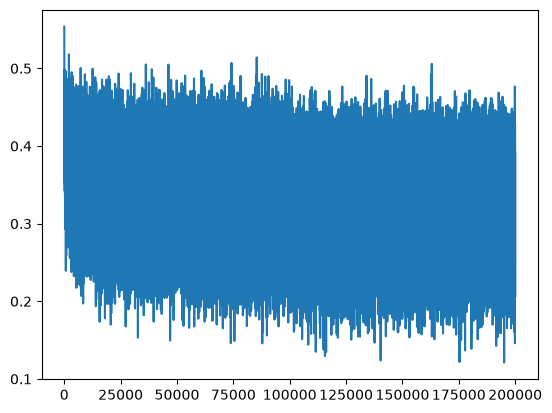

In [12]:
# parameters initialization
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 * (1/(n_embd * block_size)**0.5)
b1 = torch.randn(n_hidden,                          generator = g) * 0.1 # added back though useless
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * (1/(n_hidden)**0.5)
b2 = torch.randn(vocab_size,                        generator = g) * 0.1 # changed

bngain = torch.randn((1, n_hidden)) * 0.1 + 1.0 # changed
bnbias = torch.randn((1, n_hidden)) * 0.1 # changed

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []
eps = 1e-5
n = batch_size 


for i in range(max_steps):
    # minibatch constructions
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb] # 32, 3, 10
    embcat = emb.view(n, -1) # 32, 30
    # ---------------------linear layer 1
    hprebn = embcat @ W1 + b1 # 32, 64
    # --------------------- batchnorm layer 
    # the steps here are not done in the fast way because the manual calculation of gradients relies on the intermediate values
    bnmean = 1/n * hprebn.sum(0, keepdims = True) # 1, 64
    bndiff = hprebn - bnmean # bnmean broadcasted vertically, 32, 64
    bndiff_sq = bndiff ** 2 # 32, 64
    bnvar = 1/(n-1) * bndiff_sq.sum(0, keepdims = True) # 1, 64
    bnvar_inv = (bnvar + eps) ** -0.5 # 1, 64
    bnraw = bndiff * bnvar_inv # bnvar_inv broadcasted vertically, 32, 64
    hpreact = bngain * bnraw + bnbias # bngain and bnbias broadcasted vertically, 32, 64
    # -------------------- nonlinearity
    h = torch.tanh(hpreact) # 32, 64
    # -------------------- linear layer 2
    logits = h @ W2 + b2 # 32, 27
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    # -------------------- pytorch backpropogation
    loss.backward()
    # -------------------- manual back propogration
    dlogits = 1/n * F.softmax(logits, 1)
    dlogits[range(n), Yb] -= 1/n
    db2 = dlogits.sum(0) 
    dh = dlogits @ W2.T 
    dW2 = h.T @ dlogits 
    dhpreact = (1 - h**2) * dh 
    dbngain = (bnraw * dhpreact).sum(0, keepdims=True)
    dbnbias = dhpreact.sum(0, keepdims=True)
    dhprebn = bngain * bnvar_inv / n * (n * dhpreact - dhpreact.sum(0) - n / (n-1) * bnraw * (dhpreact * bnraw).sum(0))
    dembcat = dhprebn @ W1.T 
    db1 = dhprebn.sum(0) 
    dW1 = embcat.T @ dhprebn 
    demb = dembcat.view(n, block_size, n_embd)
    dC = torch.zeros(vocab_size, n_embd) 
    for j, index in enumerate(Xb.view(-1)):
        dC[index] += demb.view(-1, 10)[j]

    grads = [dC, dW1, db1, dW2, db2, dbngain, dbnbias]

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p, grad in zip(parameters, grads):
        # p.data -= lr * p.grad
        p.data -= lr * grad

    # tract stats: 
    if i == 0: 
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())

plt.plot(lossi)

In [13]:
for p, g in zip(parameters, grads):
    cmp(str(tuple(p.shape)), g, p)

(27, 10)        | False | approximate: True  | maxdiff: 4.470348358154297e-08
(30, 200)       | False | approximate: True  | maxdiff: 1.1175870895385742e-08
(200,)          | False | approximate: True  | maxdiff: 7.450580596923828e-09
(200, 27)       | False | approximate: True  | maxdiff: 1.862645149230957e-08
(27,)           | False | approximate: True  | maxdiff: 7.450580596923828e-09
(1, 200)        | False | approximate: True  | maxdiff: 4.6566128730773926e-09
(1, 200)        | False | approximate: True  | maxdiff: 1.1175870895385742e-08


# Substituting pytorch with manual backpropogation

12297
      1/ 200000: 3.5832
  10000/ 200000: 2.3146
  20000/ 200000: 1.6155
  30000/ 200000: 2.2885
  40000/ 200000: 2.3222
  50000/ 200000: 2.3935
  60000/ 200000: 1.6871
  70000/ 200000: 1.9230
  80000/ 200000: 2.2593
  90000/ 200000: 2.2745
 100000/ 200000: 2.1123
 110000/ 200000: 2.0382
 120000/ 200000: 1.9828
 130000/ 200000: 2.1731
 140000/ 200000: 1.9514
 150000/ 200000: 2.4910
 160000/ 200000: 2.1043
 170000/ 200000: 1.6380
 180000/ 200000: 1.6521
 190000/ 200000: 2.1019
 200000/ 200000: 2.4006


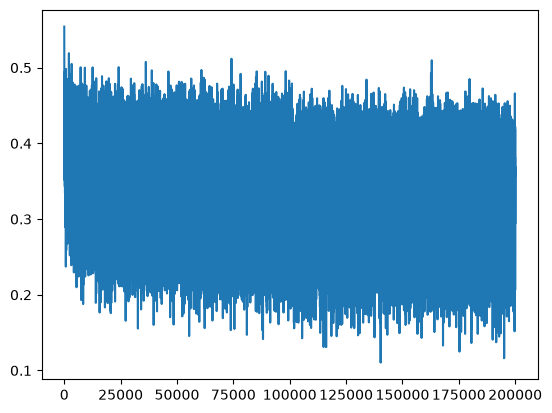

In [14]:
# parameters initialization
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 * (1/(n_embd * block_size)**0.5)
b1 = torch.randn(n_hidden,                          generator = g) * 0.1 # added back though useless
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * (1/(n_hidden)**0.5)
b2 = torch.randn(vocab_size,                        generator = g) * 0.1 # changed

bngain = torch.randn((1, n_hidden)) * 0.1 + 1.0 # changed
bnbias = torch.randn((1, n_hidden)) * 0.1 # changed

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []
eps = 1e-5
n = batch_size 

with torch.no_grad():
    for i in range(max_steps):
        # minibatch constructions
        ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
        Xb, Yb = Xtr[ix], Ytr[ix]

        # forward pass
        emb = C[Xb] # 32, 3, 10
        embcat = emb.view(n, -1) # 32, 30
        # ---------------------linear layer 1
        hprebn = embcat @ W1 + b1 # 32, 64
        # --------------------- batchnorm layer 
        # the steps here are not done in the fast way because the manual calculation of gradients relies on the intermediate values
        bnmean = 1/n * hprebn.sum(0, keepdims = True) # 1, 64
        bndiff = hprebn - bnmean # bnmean broadcasted vertically, 32, 64
        bndiff_sq = bndiff ** 2 # 32, 64
        bnvar = 1/(n-1) * bndiff_sq.sum(0, keepdims = True) # 1, 64
        bnvar_inv = (bnvar + eps) ** -0.5 # 1, 64
        bnraw = bndiff * bnvar_inv # bnvar_inv broadcasted vertically, 32, 64
        hpreact = bngain * bnraw + bnbias # bngain and bnbias broadcasted vertically, 32, 64
        # -------------------- nonlinearity
        h = torch.tanh(hpreact) # 32, 64
        # -------------------- linear layer 2
        logits = h @ W2 + b2 # 32, 27
        loss = F.cross_entropy(logits, Yb)

        # backward pass
        for p in parameters:
            p.grad = None
        # -------------------- pytorch backpropogation
        # loss.backward()
        # -------------------- manual back propogration
        dlogits = 1/n * F.softmax(logits, 1)
        dlogits[range(n), Yb] -= 1/n
        db2 = dlogits.sum(0) 
        dh = dlogits @ W2.T 
        dW2 = h.T @ dlogits 
        dhpreact = (1 - h**2) * dh 
        dbngain = (bnraw * dhpreact).sum(0, keepdims=True)
        dbnbias = dhpreact.sum(0, keepdims=True)
        dhprebn = bngain * bnvar_inv / n * (n * dhpreact - dhpreact.sum(0) - n / (n-1) * bnraw * (dhpreact * bnraw).sum(0))
        dembcat = dhprebn @ W1.T 
        db1 = dhprebn.sum(0) 
        dW1 = embcat.T @ dhprebn 
        demb = dembcat.view(n, block_size, n_embd)
        dC = torch.zeros(vocab_size, n_embd) 
        for j, index in enumerate(Xb.view(-1)):
            dC[index] += demb.view(-1, 10)[j]

        grads = [dC, dW1, db1, dW2, db2, dbngain, dbnbias]

        # update
        lr = 0.1 if i < 100000 else 0.01
        for p, grad in zip(parameters, grads):
            # p.data -= lr * p.grad
            p.data -= lr * grad

        # tract stats: 
        if i == 0: 
            print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
        if (i+1) % 10000 == 0:
            print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
        lossi.append(loss.log10().item())

plt.plot(lossi)

# Using val set and deploying the model

First we get the bnmean and bnstd on the overall training set and then use it on validation set and for deploying the model. 

In [19]:
with torch.no_grad():
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    bnmean = hpreact.mean(0, keepdims = True) 
    bnstd = hpreact.std(0, keepdims = True)

In [20]:
@torch.no_grad() # this decorator disables gradient tracking

def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    hpreact = embcat @ W1 + b1
    # hpreact = bngain * (hpreact - hpreact.mean(0, keepdims=True))/hpreact.std(0, keepdims=True) + bnbias
    # we use the mean and sd created above to calculate the same thing
    hpreact = bngain * (hpreact - bnmean)/bnstd + bnbias
    h = torch.tanh(hpreact) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.069869041442871
val 2.108109951019287


In [21]:
# sample from the model

g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        embcat = emb.view(emb.shape[0], -1)
        hpreact = embcat @ W1 + b1
        hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5) ** 0.5 + bnbias
        h = torch.tanh(hpreact)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1, generator = g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))


carlaxxleigh.
kath.
marcheltleencessa.
jazznevangelynn.
ququie.
quesis.
chaisley.
leggph.
brookindleigh.
storrett.
deba.
wraelogsofryn.
katheophus.
brextephia.
gianahliffanifa.
mohdancsy.
jamelosoz.
julion.
waxtington.
paxson.
